# Supplementary Figure 1 — HCP-YA

Figure 1's HCP-YA data (`timescales_analysis_fig1_super.ipynb`): the multi registry, 3T and 7T, 163 subjects.
**Inputs:** `timescales_process.ipynb` for HCP-YA with `modalities=['MRI3T', 'MRI7T']`, and the HCP-YA 3T
`noFIX` run when `REST_SOURCE = 'noFIX'`.

1. **Without averaging over task and movie scans**, at Figure 1's default settings (FIX-cleaned rest, the shared
   rest column).
2. **Against matched rest controls.** Figure 1's HCP-YA panels with each condition beside its own control column.
   The control is that condition's runs' `restctrl`, cut from `REST_SOURCE` rest. The 7T
   movies' controls are always FIX-cleaned rest, as the movies are. Every test pairs a condition with its own
   control.

In [1]:
import copy
import warnings
warnings.simplefilter("ignore", UserWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

%matplotlib inline

from src.notebook import (FIG1_AXIS_LABEL, FIG1_DATASET_CONFIGS, FIG1_LABELS, control_tag, data_dict_to_dataframe,
                          group_conditions, load_condition_data, load_rest_controls, reference_layout)
from src.plotting import (draw_int_rows, figure_scratch_dir, plot_repeated_measures_violins,
                          plot_subject_level_violins, setup_notebook_style)
from src.timescales import average_data_dict_converted, convert_data_dict, create_ints_dataframe_custom_grouping
from snaplab_tools.plotting.utils import save_panel, get_snap_colors

setup_notebook_style()

In [2]:
# Section 2 compares each HCP-YA condition with its matched rest control, cut from REST_SOURCE rest ('noFIX'
# lacks ICA-FIX, as the task does, 'clean' has it), except the 7T movies, whose controls always come from clean rest.
REST_SOURCE   = 'noFIX'
SFIG1_FIGSIZE = (3.5, 5)      # inches, section 2's figure

# Label of a condition's control column, shown alone in the panel and with the condition appended elsewhere so
# the two control columns stay distinct.
REFERENCE_LABEL = 'Rest\n(scan regression control)'

DATASET   = 'HCP-YA'
HCPYA     = copy.deepcopy(FIG1_DATASET_CONFIGS[DATASET])   # Figure 1's HCP-YA configuration
LABEL_MAP = copy.deepcopy(FIG1_LABELS)
brain_map = 'SA_Axis'
my_colors = get_snap_colors(cat_trio=False, as_list=True)
fig_dir = figure_scratch_dir(DATASET)

In [3]:
# One load, at Figure 1's settings; section 2 reads its controls on top of it.
loaded    = load_condition_data(DATASET, HCPYA)
processor = loaded['processor']
data_dict = loaded['data_dict']
df_neuro  = loaded['df_neuro']
print(f"{DATASET}: {len(dict.fromkeys(s.subject_id for s in processor.scan_registry))} subjects, "
      f"{len(processor.scan_registry)} scans, {loaded['output_type']}")

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-YA
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/HCP_1200
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
	Brain-gene panel 'gao': 2031/2429 symbols present in the expression matrix -> PCA input (400, 2031).
Loaded 3912 scans from scan_registry_HCP-YA_multi.csv


Loading timescale_auc_zero_crossing_resids: 100%|██████████| 3912/3912 [00:00<00:00, 8016.81it/s]

Number of subjects: 163
HCP-YA: 163 subjects, 3912 scans, timescale_auc_zero_crossing


## Section 1 — HCP-YA without averaging over task/movie scans

Default settings. Rest is collapsed: all 3T rest runs into one column, all 7T rest runs into another. Movie and task
scans keep their own columns, with phase-encoding directions averaged (each 3T task's LR/RL becomes one column; the 7T
movies are single-PE).

Supplementary scan columns (12): ['task-REST_7T', 'task-REST_3T', 'tfMRIMOVIE47TAP', 'tfMRIMOVIE37TPA', 'tfMRIMOVIE27TPA', 'tfMRIMOVIE17TAP', 'task-SOCIAL', 'task-EMOTION', 'task-GAMBLING', 'task-RELATIONAL', 'task-LANGUAGE', 'task-WM']


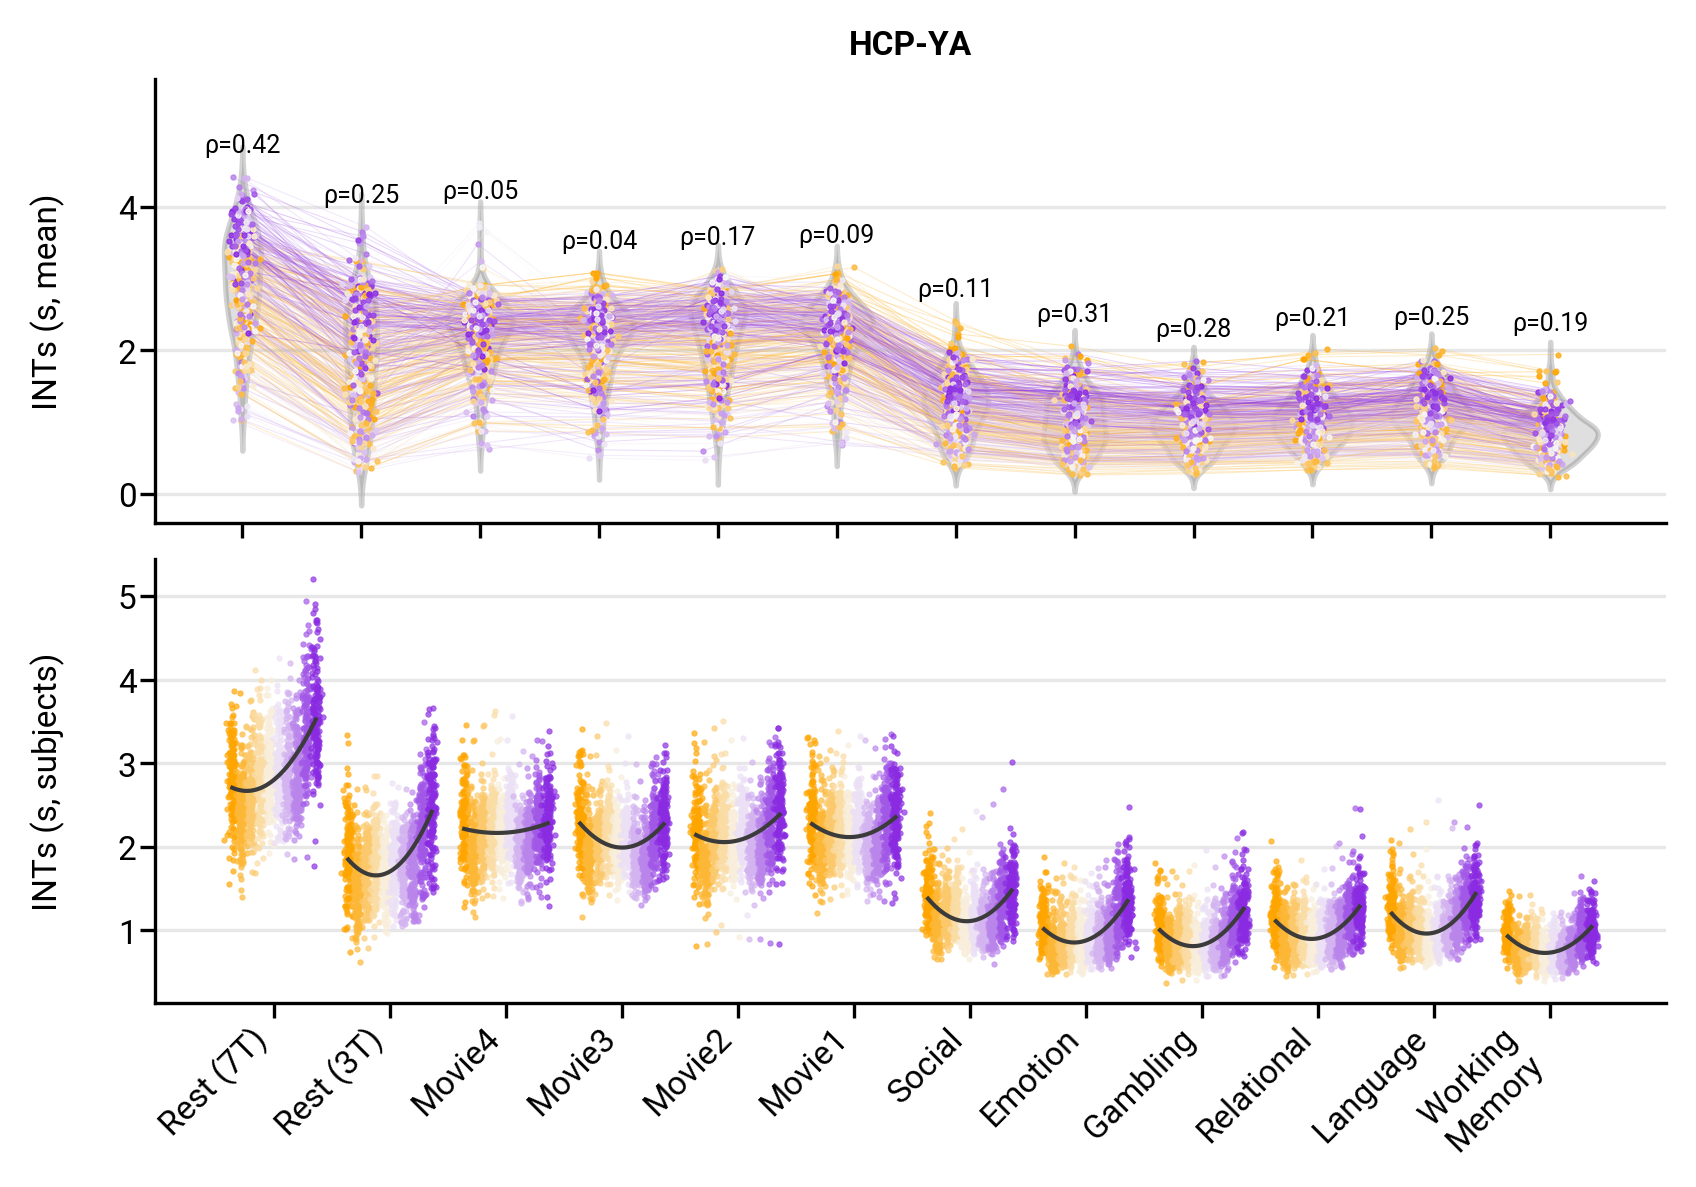

In [4]:
SORT_BY_MEDIAN = False

scan_reg_ya = processor.scan_registry
SUPP_FLAGS  = dict(average_3t_rest=True,          # all 3T rest runs -> Rest (3T)
                   average_7t_rest=True,          # all 7T rest runs -> Rest (7T)
                   average_3t_task_pairs=True)    # each task's LR/RL -> a single column

# --- Row A: regional-mean INTs, one column per scan ---
df_ints_scans = create_ints_dataframe_custom_grouping(data_dict, **SUPP_FLAGS)

# --- Row B: subject x SA-centile arrays, one column per scan ---
centiles_scans = convert_data_dict(
    data_dict, scan_reg_ya, brain_map=df_neuro[brain_map], verbose=False,
)
centiles_scans = average_data_dict_converted(centiles_scans, **SUPP_FLAGS)

# Display labels for the individual scans
SUPP_LABEL_MAP = {
    'task-REST_7T':    'Rest (7T)',
    'task-REST_3T':    'Rest (3T)',
    'tfMRIMOVIE47TAP': 'Movie4',
    'tfMRIMOVIE37TPA': 'Movie3',
    'tfMRIMOVIE27TPA': 'Movie2',
    'tfMRIMOVIE17TAP': 'Movie1',
    'task-SOCIAL':     'Social',
    'task-EMOTION':    'Emotion',
    'task-GAMBLING':   'Gambling',
    'task-RELATIONAL': 'Relational',
    'task-LANGUAGE':   'Language',
    'task-WM':         'Working\nMemory',
}

# Column order, derived once and applied to both rows so they stay aligned.
present_keys = [k for k in SUPP_LABEL_MAP if k in df_ints_scans.columns]
if SORT_BY_MEDIAN:
    supp_order = (
        df_ints_scans[present_keys].median(axis=0)
        .sort_values(ascending=False).index.tolist()
    )
else:
    supp_order = present_keys
print(f'Supplementary scan columns ({len(supp_order)}): {supp_order}')

# Order + rename Row A
df_ints_scans = df_ints_scans[supp_order].rename(columns=SUPP_LABEL_MAP)

# Order + rename Row B (same order as Row A)
df_centiles_scans = data_dict_to_dataframe(centiles_scans)
cond_cols = [c for c in df_centiles_scans.columns if c != 'subject']
df_centiles_scans = df_centiles_scans[['subject'] + [c for c in supp_order if c in cond_cols]]
df_centiles_scans = df_centiles_scans.rename(columns=SUPP_LABEL_MAP)

# --- Figure ---
n_conds = len(df_ints_scans.columns)
fig = plt.figure(figsize=(0.5 * n_conds + 0.5, 4), dpi=300)
gs  = gridspec.GridSpec(2, 1, hspace=0.08)

ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[1, 0])

# --- Row A: regional mean violins ---
ax0 = plot_repeated_measures_violins(
    df_ints_scans, ax0,
    color_vector=df_neuro[brain_map], colormap='snap_sydnor_sa',
    add_colorbar=False,
    point_alpha=1, line_alpha=0.3, point_size=0.25, line_width=0.25,
    violin_alpha=0.25, correlation_method='spearman', annotate_variance=False,
)
ax0.set_xticklabels([])
ax0.set_xlabel('')
ax0.set_title('HCP-YA', fontsize=8, fontweight='bold')
ax0.set_ylabel(FIG1_AXIS_LABEL.format('mean'), fontsize=8)

# --- Row B: subject-level centile scatter ---
# sort_by_median stays False, because re-sorting by the centile median would de-align Row B from Row A.
ax1, _ = plot_subject_level_violins(
    df_centiles_scans, ax1, np.arange(10),
    point_alpha=0.75, point_size=0.25,
    show_violins=False, show_lines=False, fit_trends=True,
    show_r2_annotation=False, annotate_variance=False,
    hide_legend=True, sort_by_median=False,
)
ax1.set_xlabel('')
ax1.set_ylabel(FIG1_AXIS_LABEL.format('subjects'), fontsize=8)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right', fontsize=8)

for ax in [ax0, ax1]:
    ax.tick_params(axis='y', which='major', pad=1)
    ax.tick_params(axis='x', which='major', pad=1)
    ax.yaxis.set_label_coords(-0.06, 0.5)

plt.tight_layout()

if HCPYA.get('filter') == 'bp-0.01-0.08hz':
    fig_label = 'timescales_analysis_fig1_hcpya_scans_bp'
else:
    fig_label = 'timescales_analysis_fig1_hcpya_scans'

save_panel(fig, fig_dir, fig_label, transparent=True)
plt.show()

## Section 2 — HCP-YA against matched rest controls

Figure 1's HCP-YA top block, with each condition paired with its own control column:

- **A:** regional-mean INTs, each condition with a paired t-test against its control (parcels paired). BH-FDR across
  HCP-YA's two conditions only.
- **B:** subject-level INTs across S-A deciles.

In [5]:
# Each condition's matched rest controls (load_rest_controls), dropping and counting any subject missing one.
TAG = control_tag(REST_SOURCE)
conditions = HCPYA['custom_order'][1:]
data_dict_ctrl, controls, dropped = load_rest_controls(processor, data_dict, conditions, rest_source=REST_SOURCE,
                                                       filter=HCPYA.get('filter'))
order, reference_of = reference_layout(HCPYA['custom_order'], controls=True)
for cond, ref in reference_of.items():
    LABEL_MAP[ref] = f"{REFERENCE_LABEL}, {LABEL_MAP.get(cond, cond)}"
dropped_per_condition = pd.DataFrame(
    [{'condition': LABEL_MAP.get(c, c).replace(chr(10), ' '), 'subjects dropped': len(dropped[c])}
     for c in conditions])
print(dropped_per_condition.to_string(index=False))

grouped = group_conditions(processor, data_dict_ctrl, df_neuro, HCPYA, brain_map=brain_map, order=order,
                           controls=controls)
print(f"file tag: {TAG!r}; columns: {grouped['df_ints'].columns.tolist()}; "
      f"{len(grouped['subject_ids'])} subjects")

Loading timescale_auc_zero_crossing_restctrl: 100%|██████████| 3912/3912 [00:00<00:00, 10880.43it/s]
Loading timescale_auc_zero_crossing_noFIX_restctrl: 100%|██████████| 3912/3912 [00:00<00:00, 13888.80it/s]


  matched rest controls (noFIX): task-Movies: 0 subjects dropped; task-WM: 0 subjects dropped
     condition  subjects dropped
        Movies                 0
Working Memory                 0
file tag: '_rest-noFIX_cmp-restctrl'; columns: ['ref:task-Movies', 'task-Movies', 'ref:task-WM', 'task-WM']; 163 subjects


                   n  dof  mean_diff          t              p         p_corr  \
condition                                                                       
Movies           400  399  -0.052999  -3.681874   2.633836e-04   2.633836e-04   
Working\nMemory  400  399  -0.348544 -37.497901  7.543362e-133  1.508672e-132   

                 sig  
condition             
Movies           ***  
Working\nMemory  ***  


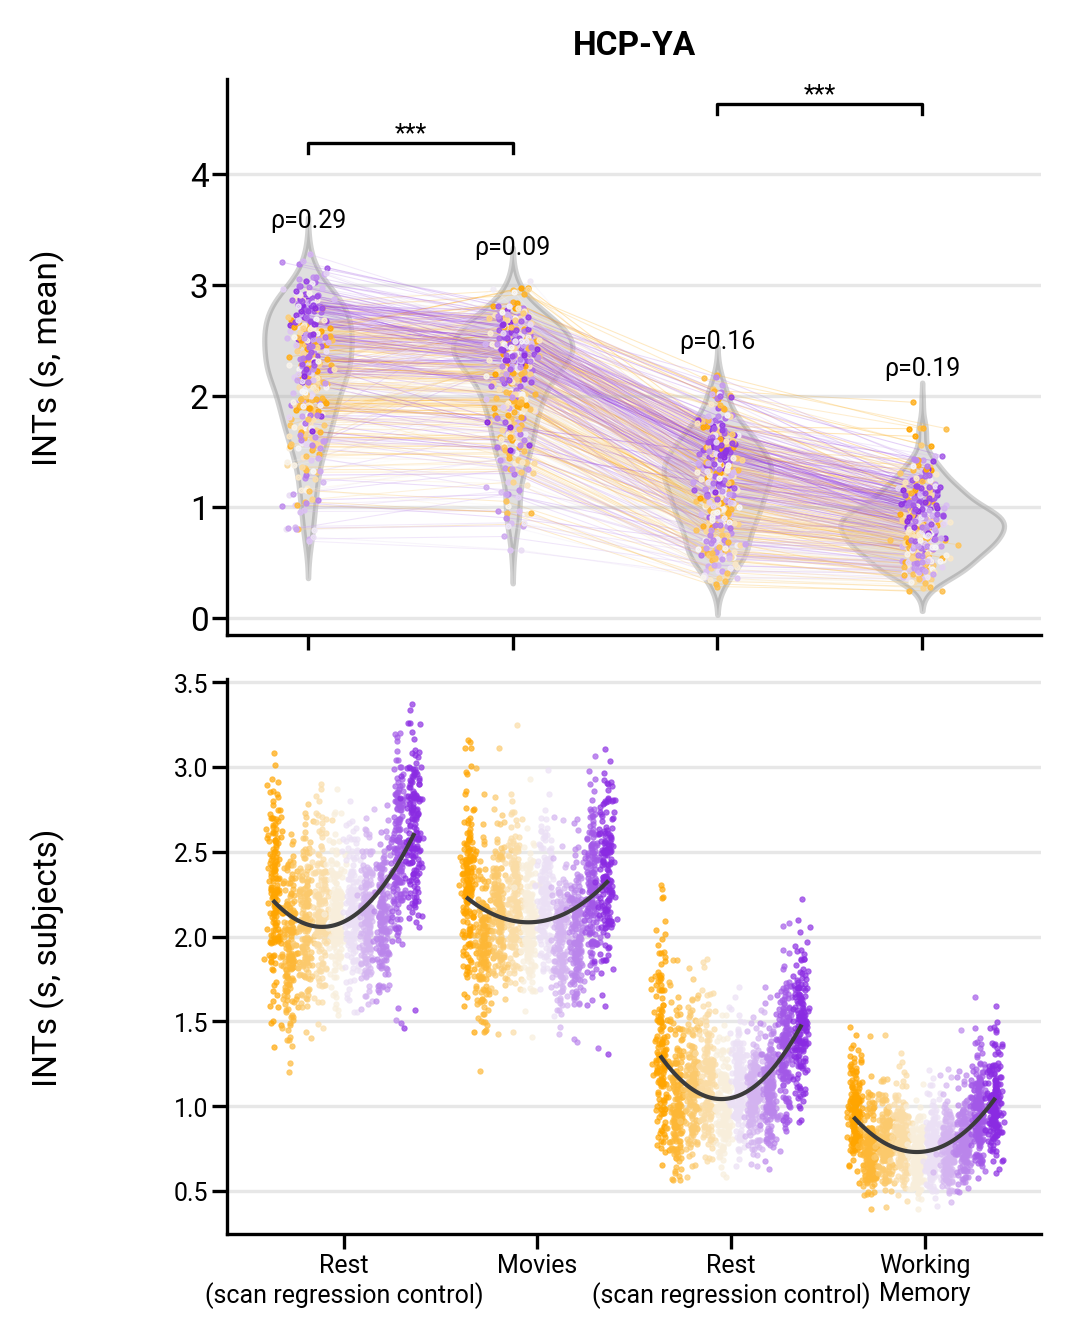

In [6]:
# Figure: rows A and B as Figure 1's HCP-YA column.
fig = plt.figure(figsize=SFIG1_FIGSIZE, dpi=300)
rows = gridspec.GridSpec(2, 1, hspace=0.08)

ax_b = fig.add_subplot(rows[1, 0])
ttests = draw_int_rows(fig.add_subplot(rows[0, 0]), ax_b, grouped['df_ints'],
                       grouped['data_dict_centiles'], reference_of, df_neuro[brain_map], LABEL_MAP, HCPYA['title'],
                       ylabels=tuple(FIG1_AXIS_LABEL.format(k) for k in ('mean', 'subjects')))
# The panel names each control by REFERENCE_LABEL alone: it sits beside its own condition.
ax_b.set_xticklabels([REFERENCE_LABEL if c in reference_of.values() else LABEL_MAP.get(c, c)
                      for c in grouped['df_ints'].columns], fontsize=ax_b.get_xticklabels()[0].get_fontsize())

plt.tight_layout()
save_panel(fig, fig_dir, f'timescales_analysis_sfig1_hcpya{TAG}', transparent=True)
plt.show()